# SPARK Prediction Pipeline

Run CellSAM segmentation + mask post-processing + SPARK quantification
for a list of `.tif` files and save results to a shared HDF5 store.

**Steps per file:**
1. Load TIFF (auto channel detection)
2. CellSAM segmentation
3. Mask post-processing (size filter + reference merge + interpolation)
4. SPARK quantification
5. Normalisation
6. Save to HDF5

In [1]:
import sys, os, json
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd

sys.path.append('.')           # spark_utils.py must be in the same directory
sys.path.append('../data-registry/cli/')

from spark_utils import (
    load_tiff_as_grayscale, make_read_frame,
    run_cellsam_segmentation,
    postprocess_masks, interpolate_missing_masks,
    quantify_spark, normalise_spark,
    save_to_hdf5,
)


In [2]:
# ── load CellSAM model (run once) ───────────────────────────────────────
model_weight_path = './.cellsam_assets/mixed_model_inference_balanced.pth'
model = torch.load(model_weight_path, map_location=torch.device('cpu'))
model.bbox_threshold = 0.4 / 1.05
model.mask_threshold = 0.4 / 5.05
model.iou_threshold  = 0.5 / 1.05
model = model.eval().cuda()


In [3]:
# ── load and merge all CSV mappings ──────────────────────────────────────────
import os, h5py
import pandas as pd
 
CSV_V1    = './tif_file_mapping.csv'
CSV_V2    = './tif_file_mapping_v2.csv'
CSV_V3    = './tif_file_mapping_v3.csv'
CSV_V4    = './tif_file_mapping_v4.csv'
OUTPUT_H5 = '${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5'
os.makedirs(os.path.dirname(OUTPUT_H5), exist_ok=True)
 
# ── normalise v1 schema → common format ──────────────────────────────────────
df_v1 = pd.read_csv(CSV_V1)
df_v1 = df_v1.rename(columns={'matched_files': 'filepath'})
df_v1['run_key'] = df_v1['file_id']
 
# ── normalise v2/v3/v4 schema → common format ────────────────────────────────
def load_vn(csv_path):
    df = pd.read_csv(csv_path)
    df['run_key'] = (df['date'].astype(str) + '_' +
                     df['plate'].astype(str) + '_xy' +
                     df['xy'].astype(str).str.zfill(2))
    return df
 
df_v2 = load_vn(CSV_V2)
df_v3 = load_vn(CSV_V3)
df_v4 = load_vn(CSV_V4)
 
# ── combine, deduplicate by filepath ─────────────────────────────────────────
df_combined = pd.concat([
    df_v1[['run_key', 'reporter', 'condition', 'filepath']],
    df_v2[['run_key', 'reporter', 'condition', 'filepath']],
    df_v3[['run_key', 'reporter', 'condition', 'filepath']],
    df_v4[['run_key', 'reporter', 'condition', 'filepath']],
], ignore_index=True).drop_duplicates(subset='filepath')
 
print(f'v1: {len(df_v1)} entries')
print(f'v2: {len(df_v2)} entries')
print(f'v3: {len(df_v3)} entries')
print(f'v4: {len(df_v4)} entries')
print(f'combined (deduplicated by filepath): {len(df_combined)} entries')
 
# ── check what is already in the HDF5 ────────────────────────────────────────
def get_existing_keys(h5_path):
    if not os.path.exists(h5_path):
        return set()
    with h5py.File(h5_path, 'r') as hf:
        return set(hf.keys())
 
existing_keys = get_existing_keys(OUTPUT_H5)
new_entries   = df_combined[~df_combined['run_key'].isin(existing_keys)]
print(f'\nAlready in HDF5:  {len(existing_keys)} runs')
print(f'New to process:   {len(new_entries)} runs')
print(new_entries[['run_key', 'reporter', 'condition']].to_string(index=False))
 
# ── build EXPERIMENTS from new entries only ───────────────────────────────────
TIMING = {
    'tbk1':              {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0},
    'tbk1-novel':        {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0},
    'ikkb':              {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0},
    'ikkb-novel':        {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0},
    'TBK-SPK-1':         {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0},
    'TBK-SPK-novel':     {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0},
    'TBK-SPK-1-TA':      {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0},
    'TBK-SPK-novel-TA':  {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0},
    'IKK-SPK-1':         {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0},
    'IKK-SPK-novel':     {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0},
    'IKK-SPK-1-TA':      {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0},
}
 
EXPERIMENTS = []
for _, row in new_entries.iterrows():
    timing = TIMING.get(row['reporter'], {'minutes_per_frame': 4.0, 'frame_offset_min': 0.0})
    EXPERIMENTS.append({
        'path':              row['filepath'],
        'run_key':           row['run_key'],
        'reporter':          row['reporter'],
        'condition':         row['condition'],
        'channel':           None,
        'minutes_per_frame': timing['minutes_per_frame'],
        'frame_offset_min':  timing['frame_offset_min'],
        'norm_frame':        None,
        'ctrl_cell_ids':     None,
    })
 
print(f'\nBuilt {len(EXPERIMENTS)} experiments to run.')
 
# ── shared parameters ─────────────────────────────────────────────────────────
SPARK_PARAMS = {
    'puncta_cell_percentile': 99,
    'min_puncta_size':        5,
    'max_puncta_size':        1500,
    'min_puncta_mean_int':    2600,
}

# ── dim-reporter parameters (IKK-SPK-novel TNFa / polyIC) ────────────────────
# These FOVs are generally dimmer; use two-threshold detection with a lower
# absolute floor instead of the standard global min_puncta_mean_int.
SPARK_PARAMS_DIM = {
    'puncta_cell_percentile': 99,
    'min_puncta_size':        4,
    'max_puncta_size':        1500,
    'min_puncta_mean_int':    750,
    'puncta_low_floor':       800,   # expansion floor for two-threshold method
}

# Conditions that need the dim quantification
DIM_REPORTER_CONDITIONS = {
    ('IKK-SPK-novel', 'TNFa'),
    ('IKK-SPK-novel', 'polyIC'),
}

# Force reprocess: delete existing HDF5 entries for these reporter/condition
# pairs so they get re-quantified with the new thresholds.
def get_runs_to_reprocess(h5_path, reporter_conditions):
    """Return run_keys already in HDF5 that match reporter/condition pairs."""
    runs = []
    if not os.path.exists(h5_path):
        return runs
    with h5py.File(h5_path, 'r') as hf:
        for rk in hf.keys():
            meta = json.loads(hf[rk].attrs.get('metadata', '{}'))
            rep  = meta.get('reporter', '')
            cond = meta.get('condition', '')
            if (rep, cond) in reporter_conditions:
                runs.append(rk)
    return runs

reprocess_keys = set(get_runs_to_reprocess(OUTPUT_H5, DIM_REPORTER_CONDITIONS))
if reprocess_keys:
    print(f'Will reprocess {len(reprocess_keys)} existing runs with dim parameters:')
    for rk in sorted(reprocess_keys):
        print(f'  {rk}')
    # Remove from HDF5 so the loop reprocesses them
    with h5py.File(OUTPUT_H5, 'a') as hf:
        for rk in reprocess_keys:
            if rk in hf:
                del hf[rk]
    print('Deleted from HDF5 — will be reprocessed in loop.')
else:
    print('No existing dim runs to reprocess.')
 
SEG_PARAMS = {
    'clip_max':          3000,
    'min_cell_size_px':  5000,
    'iou_thresh':        0.3,
    'ioq_thresh':        0.2,
    'dilation_px':       20,
    'max_interp_gap':    4,
}

v1: 22 entries
v2: 110 entries
v3: 32 entries
v4: 39 entries
combined (deduplicated by filepath): 190 entries

Already in HDF5:  188 runs
New to process:   2 runs
             run_key         reporter condition
20250126_plate1_xy62 TBK-SPK-novel-TA    diABZI
20250130_plate1_xy44     TBK-SPK-1-TA    diABZI

Built 2 experiments to run.
Will reprocess 11 existing runs with dim parameters:
  240815_plate4_xy42
  240815_plate4_xy55
  240815_plate4_xy56
  240815_plate4_xy58
  240815_plate4_xy63
  240815_plate4_xy64
  240822_plate2_xy47
  240822_plate2_xy48
  240822_plate2_xy50
  240822_plate2_xy51
  240822_plate2_xy52
Deleted from HDF5 — will be reprocessed in loop.


In [4]:
exp

NameError: name 'exp' is not defined

Skipping 20250130_plate1_xy04 (already in HDF5)
Skipping 20250130_plate1_xy05 (already in HDF5)
Skipping 20250130_plate1_xy07 (already in HDF5)
Skipping 20250130_plate1_xy13 (already in HDF5)
Skipping 20250130_plate1_xy20 (already in HDF5)
Skipping 20250130_plate1_xy16 (already in HDF5)
Skipping 20250130_plate1_xy18 (already in HDF5)
Skipping 20250130_plate1_xy26 (already in HDF5)
Skipping 20250130_plate1_xy27 (already in HDF5)
Skipping 20250130_plate1_xy28 (already in HDF5)
Skipping 20250130_plate1_xy30 (already in HDF5)
Skipping 20250130_plate1_xy32 (already in HDF5)
Skipping 20250130_plate1_xy34 (already in HDF5)
Skipping 20250130_plate1_xy35 (already in HDF5)
Skipping 20250130_plate1_xy36 (already in HDF5)
Skipping 20250130_plate1_xy39 (already in HDF5)
Skipping 20250130_plate1_xy40 (already in HDF5)
Skipping 20250130_plate1_xy43 (already in HDF5)

Processing: 20250130_plate1_xy44  [TBK-SPK-1-TA / diABZI]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=88  max=2281  mean=1

CellSAM segmentation:   2%|▋                                        | 1/61 [00:00<00:44,  1.36it/s]

  no mask found at frame 0


CellSAM segmentation:   7%|██▋                                      | 4/61 [00:02<00:41,  1.36it/s]

  no mask found at frame 3


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:46<00:00,  1.31it/s]


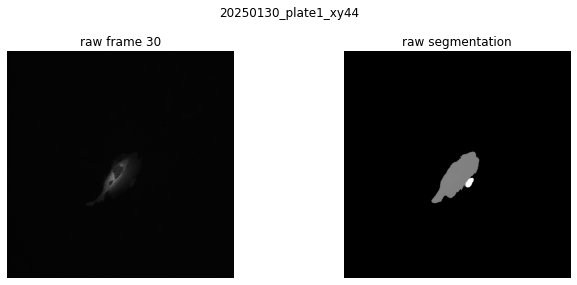

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:06<00:00,  8.76it/s]


tracked_masks: (61, 1608, 1608)  cells=[]


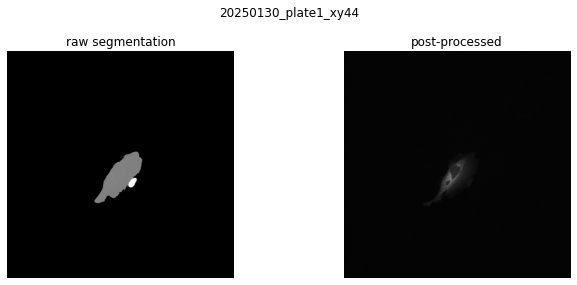

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:07<00:00,  7.87it/s]



Processing: 20250130_plate1_xy50  [TBK-SPK-1-TA / diABZI]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=85  max=1826  mean=130.0


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:47<00:00,  1.28it/s]


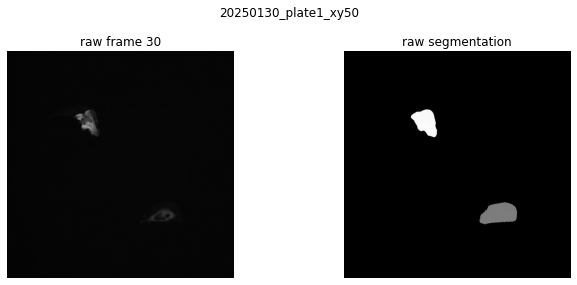

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:05<00:00, 10.21it/s]


tracked_masks: (61, 1608, 1608)  cells=[1 2]


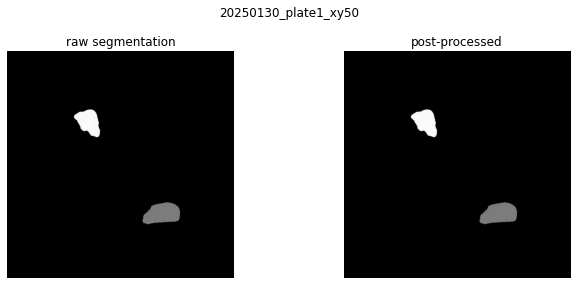

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:13<00:00,  4.62it/s]


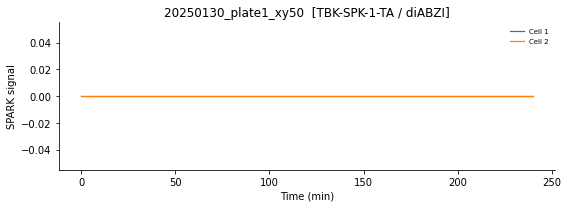

Saving run: 20250130_plate1_xy50
  spark_df: 122 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:12<00:00,  4.83it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (257.6 MB)
  done: 20250130_plate1_xy50

Processing: 20250130_plate1_xy53  [TBK-SPK-1-TA / diABZI]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=93  max=789  mean=129.4


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:47<00:00,  1.28it/s]


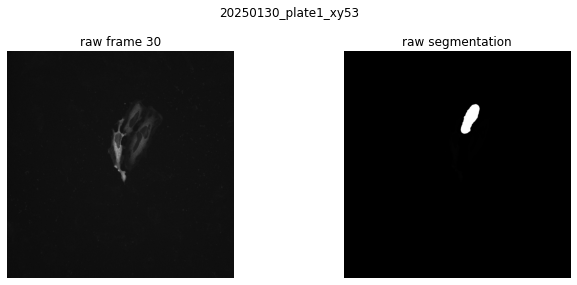

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:07<00:00,  7.73it/s]


  cell 1: interpolating frames 16–16
  cell 1: interpolating frames 20–20
  cell 2: interpolating frames 3–3
  cell 2: interpolating frames 14–16
  cell 2: gap 19–23 (5 frames) too large, skipping
  cell 2: interpolating frames 25–26
  cell 2: interpolating frames 29–31
  cell 2: interpolating frames 42–42
  cell 2: interpolating frames 45–45
  cell 2: gap 47–51 (5 frames) too large, skipping
  cell 2: interpolating frames 54–54
  cell 2: interpolating frames 57–57
tracked_masks: (61, 1608, 1608)  cells=[1 2]


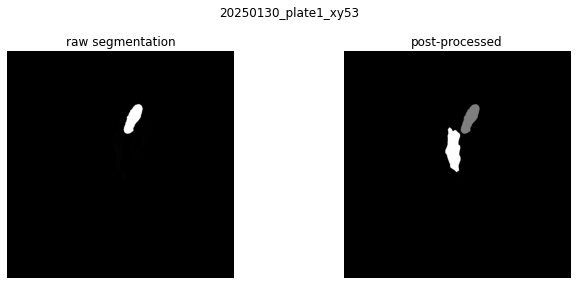

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:12<00:00,  4.83it/s]


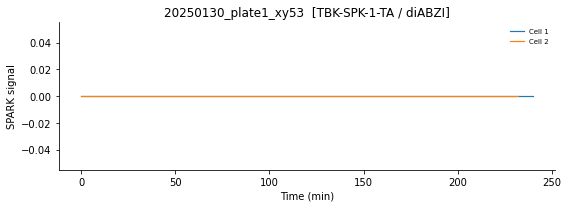

Saving run: 20250130_plate1_xy53
  spark_df: 110 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:12<00:00,  4.98it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (258.3 MB)
  done: 20250130_plate1_xy53

Processing: 20250130_plate1_xy45  [TBK-SPK-1-TA / LPS]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=92  max=891  mean=127.6


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:45<00:00,  1.34it/s]


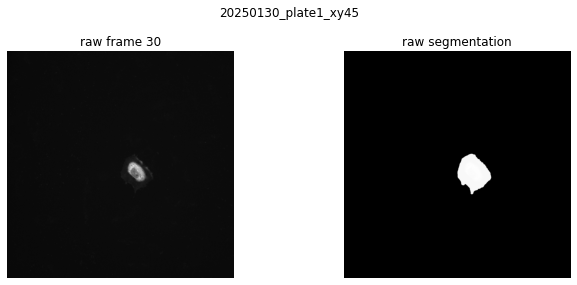

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:05<00:00, 12.01it/s]


tracked_masks: (61, 1608, 1608)  cells=[1]


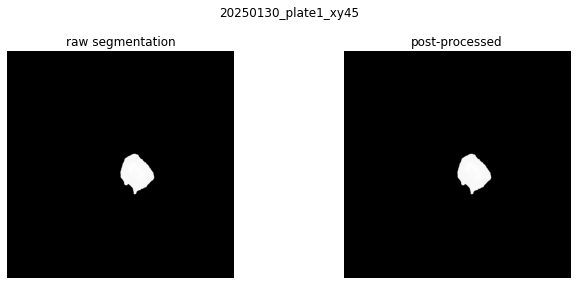

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:10<00:00,  5.65it/s]


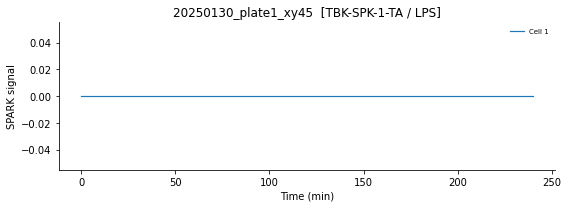

Saving run: 20250130_plate1_xy45
  spark_df: 61 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:10<00:00,  5.82it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (258.8 MB)
  done: 20250130_plate1_xy45

Processing: 20250130_plate1_xy55  [TBK-SPK-1-TA / LPS]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=88  max=753  mean=129.2


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:52<00:00,  1.15it/s]


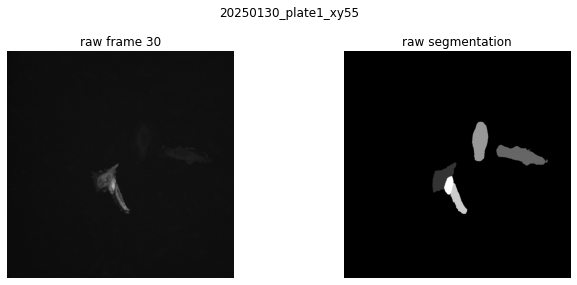

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:12<00:00,  5.00it/s]


  cell 1: interpolating frames 59–59
  cell 2: interpolating frames 21–21
  cell 2: interpolating frames 47–48
  cell 2: interpolating frames 53–54
  cell 5: interpolating frames 1–2
  cell 5: interpolating frames 39–41
  cell 5: interpolating frames 43–44
  cell 5: interpolating frames 46–46
  cell 5: interpolating frames 49–51
  cell 5: interpolating frames 56–56
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4 5]


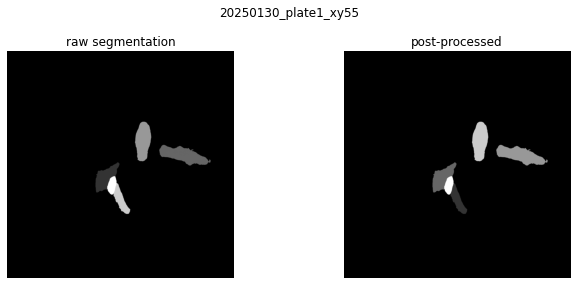

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:20<00:00,  3.04it/s]


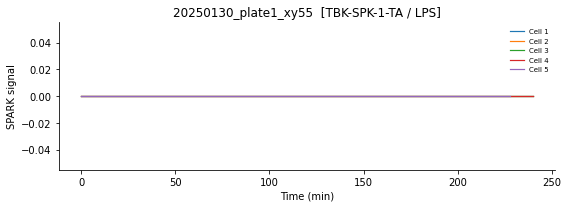

Saving run: 20250130_plate1_xy55
  spark_df: 302 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:19<00:00,  3.20it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (259.6 MB)
  done: 20250130_plate1_xy55

Processing: 20250130_plate1_xy57  [TBK-SPK-1-TA / LPS]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=89  max=1547  mean=130.2


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:45<00:00,  1.33it/s]


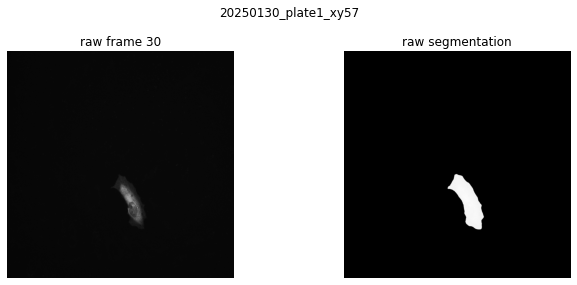

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:05<00:00, 11.30it/s]


tracked_masks: (61, 1608, 1608)  cells=[1]


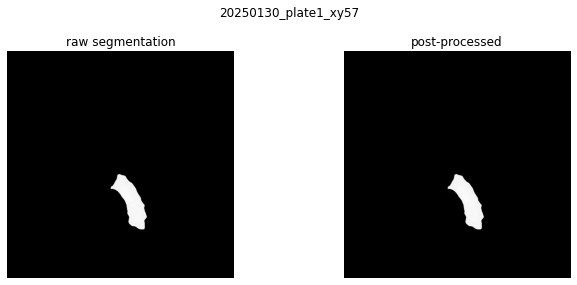

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:10<00:00,  5.76it/s]


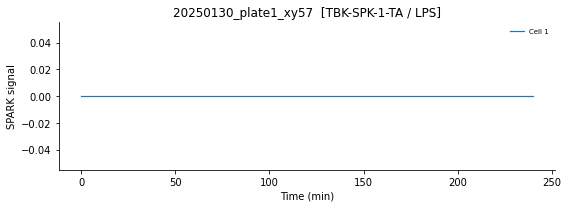

Saving run: 20250130_plate1_xy57
  spark_df: 61 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:10<00:00,  5.98it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (260.1 MB)
  done: 20250130_plate1_xy57

Processing: 20250130_plate1_xy58  [TBK-SPK-1-TA / LPS]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=86  max=658  mean=128.6


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:53<00:00,  1.13it/s]


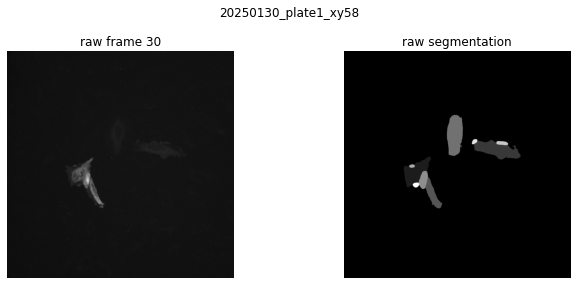

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:15<00:00,  3.94it/s]


  cell 1: interpolating frames 4–4
  cell 1: interpolating frames 6–9
  cell 1: interpolating frames 11–11
  cell 1: interpolating frames 19–19
  cell 1: interpolating frames 22–22
  cell 1: interpolating frames 24–24
  cell 1: interpolating frames 28–28
  cell 1: interpolating frames 30–30
  cell 1: interpolating frames 32–32
  cell 1: interpolating frames 47–49
  cell 1: interpolating frames 53–53
  cell 5: interpolating frames 2–2
  cell 5: interpolating frames 31–31
  cell 5: interpolating frames 39–41
  cell 5: interpolating frames 43–46
  cell 5: interpolating frames 50–52
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4 5]


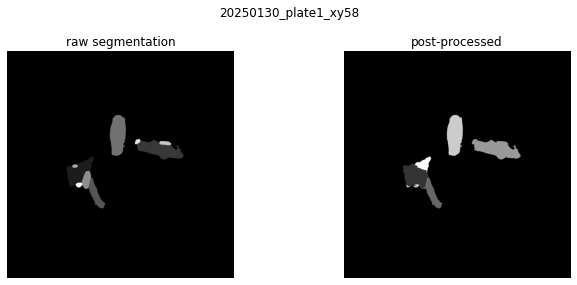

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:19<00:00,  3.09it/s]


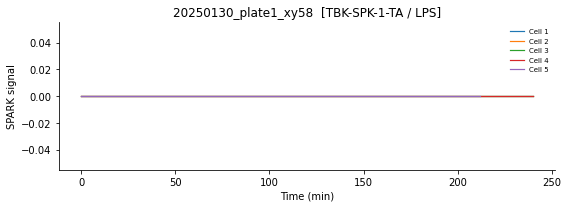

Saving run: 20250130_plate1_xy58
  spark_df: 298 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:18<00:00,  3.27it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (261.0 MB)
  done: 20250130_plate1_xy58

Processing: 20250130_plate1_xy60  [TBK-SPK-novel / blank]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=89  max=546  mean=126.9


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:47<00:00,  1.27it/s]


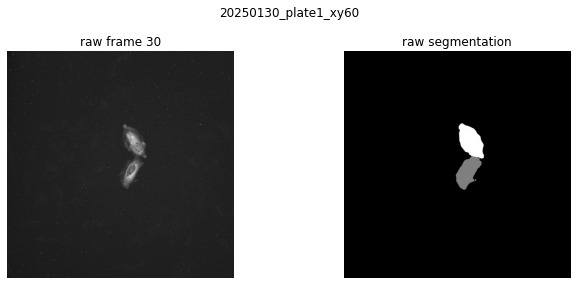

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:06<00:00,  9.98it/s]


  cell 1: interpolating frames 23–23
  cell 2: interpolating frames 34–34
tracked_masks: (61, 1608, 1608)  cells=[1 2]


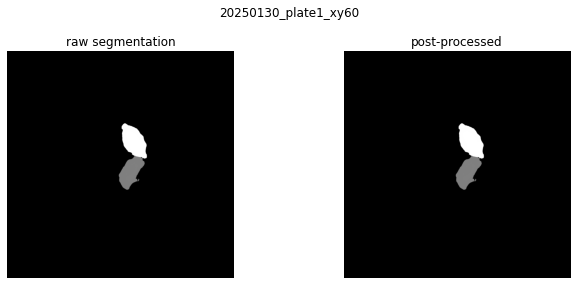

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:13<00:00,  4.59it/s]


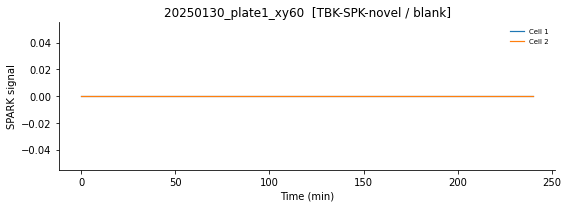

Saving run: 20250130_plate1_xy60
  spark_df: 122 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:12<00:00,  4.83it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (261.6 MB)
  done: 20250130_plate1_xy60

Processing: 20250130_plate1_xy61  [TBK-SPK-novel / blank]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=90  max=18611  mean=135.9


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:46<00:00,  1.32it/s]


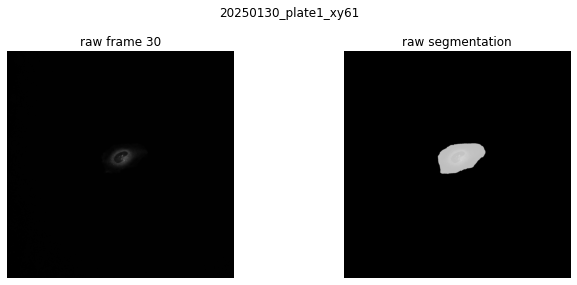

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:05<00:00, 12.06it/s]


tracked_masks: (61, 1608, 1608)  cells=[1]


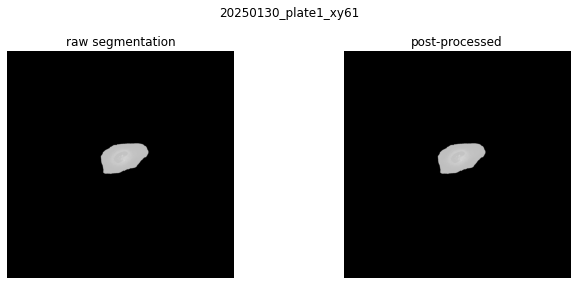

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:10<00:00,  5.75it/s]


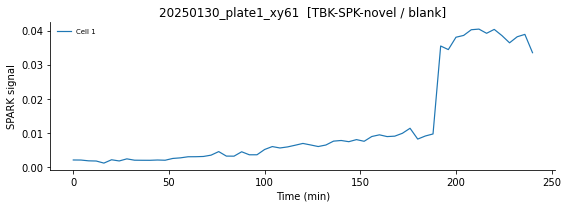

Saving run: 20250130_plate1_xy61
  spark_df: 61 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:10<00:00,  5.92it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (262.2 MB)
  done: 20250130_plate1_xy61

Processing: 20250130_plate1_xy62  [TBK-SPK-novel / GSK-8612]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=91  max=964  mean=128.3


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:51<00:00,  1.19it/s]


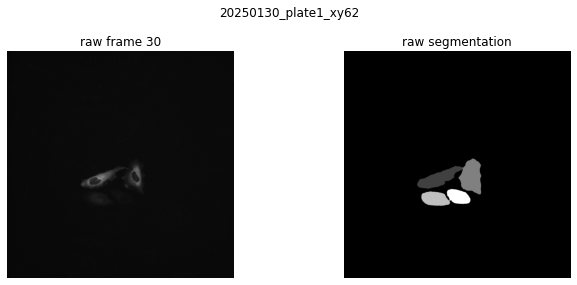

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:08<00:00,  7.47it/s]


tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4]


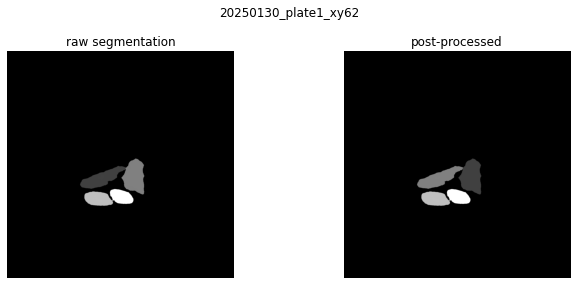

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:18<00:00,  3.33it/s]


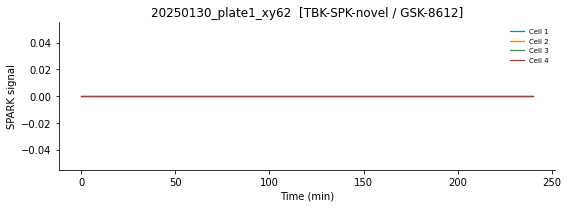

Saving run: 20250130_plate1_xy62
  spark_df: 244 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:17<00:00,  3.53it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (262.9 MB)
  done: 20250130_plate1_xy62

Processing: 20250130_plate1_xy104  [TBK-SPK-novel / LPS]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=90  max=524  mean=124.8


CellSAM segmentation:  44%|█████████████████▋                      | 27/61 [00:21<00:26,  1.28it/s]

  no mask found at frame 26


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:48<00:00,  1.27it/s]


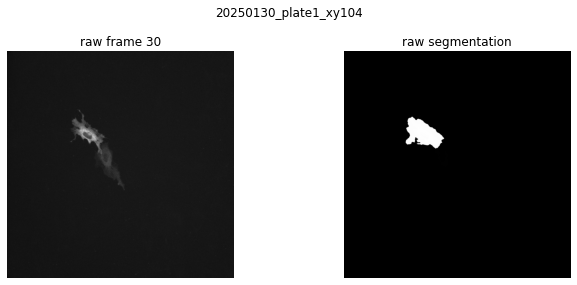

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:07<00:00,  8.64it/s]


  cell 1: interpolating frames 26–26
tracked_masks: (61, 1608, 1608)  cells=[1]


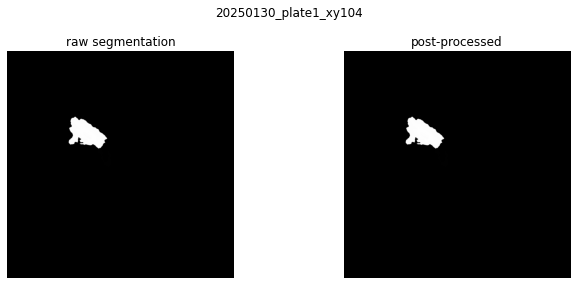

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:10<00:00,  5.71it/s]


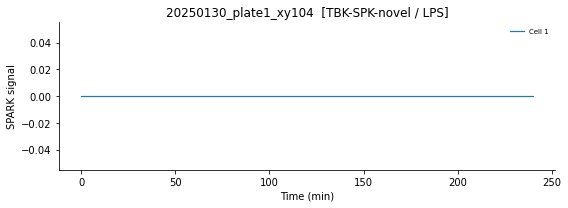

Saving run: 20250130_plate1_xy104
  spark_df: 61 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:10<00:00,  5.82it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (263.5 MB)
  done: 20250130_plate1_xy104

Processing: 20250130_plate1_xy79  [TBK-SPK-novel-TA / blank]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=86  max=870  mean=129.8


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:47<00:00,  1.29it/s]


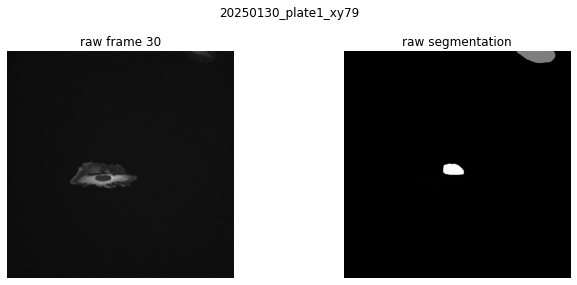

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:06<00:00,  9.96it/s]


tracked_masks: (61, 1608, 1608)  cells=[1]


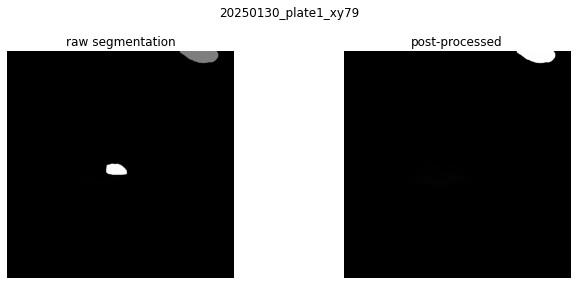

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:10<00:00,  5.92it/s]


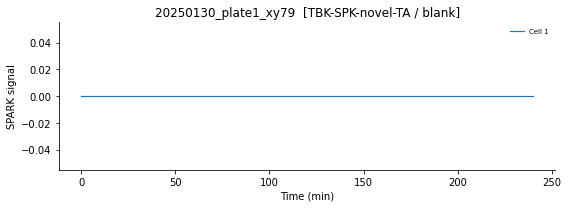

Saving run: 20250130_plate1_xy79
  spark_df: 61 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:10<00:00,  6.04it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (264.0 MB)
  done: 20250130_plate1_xy79

Processing: 20250130_plate1_xy80  [TBK-SPK-novel-TA / blank]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=83  max=1573  mean=130.8


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:53<00:00,  1.15it/s]


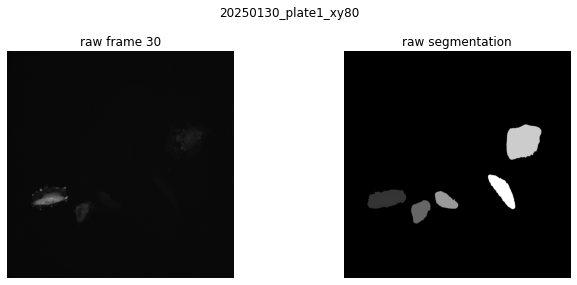

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:13<00:00,  4.43it/s]


  cell 3: interpolating frames 58–58
  cell 5: gap 1–25 (25 frames) too large, skipping
  cell 5: interpolating frames 27–27
  cell 5: interpolating frames 29–29
  cell 5: interpolating frames 37–37
  cell 5: interpolating frames 46–46
  cell 5: interpolating frames 54–55
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 4 5]


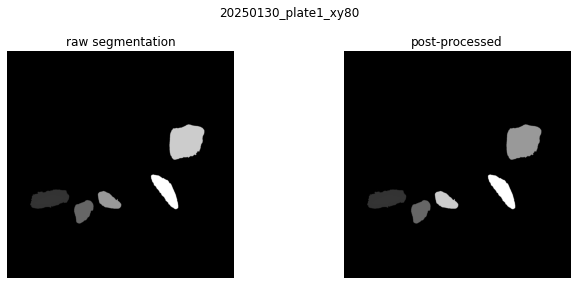

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:19<00:00,  3.15it/s]


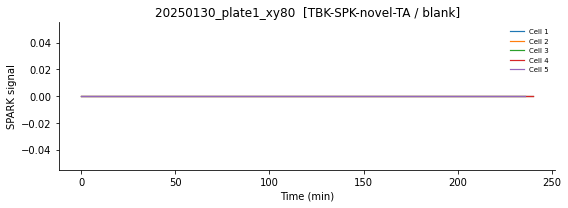

Saving run: 20250130_plate1_xy80
  spark_df: 278 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:18<00:00,  3.31it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (264.7 MB)
  done: 20250130_plate1_xy80

Processing: 20250130_plate1_xy81  [TBK-SPK-novel-TA / blank]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=87  max=1719  mean=132.5


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:54<00:00,  1.11it/s]


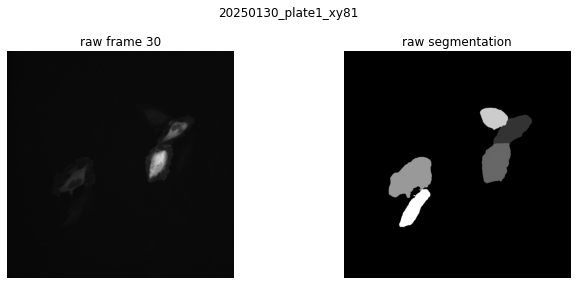

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:18<00:00,  3.32it/s]


  cell 6: interpolating frames 29–31
  cell 6: interpolating frames 37–38
  cell 7: interpolating frames 1–2
  cell 7: interpolating frames 11–11
  cell 7: interpolating frames 15–15
  cell 7: gap 21–26 (6 frames) too large, skipping
  cell 7: gap 28–32 (5 frames) too large, skipping
  cell 7: interpolating frames 34–36
  cell 7: interpolating frames 38–38
  cell 7: interpolating frames 40–40
  cell 7: interpolating frames 43–43
  cell 7: interpolating frames 49–49
  cell 7: interpolating frames 51–53
  cell 7: interpolating frames 56–56
tracked_masks: (61, 1608, 1608)  cells=[1 2 3 5 6 7 8]


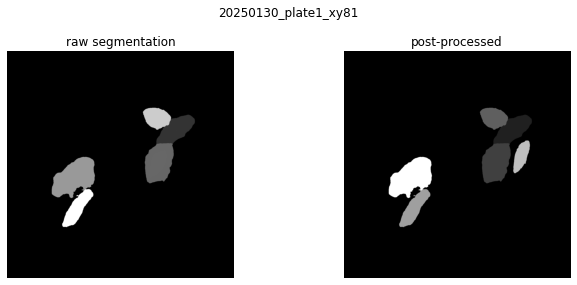

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:24<00:00,  2.51it/s]


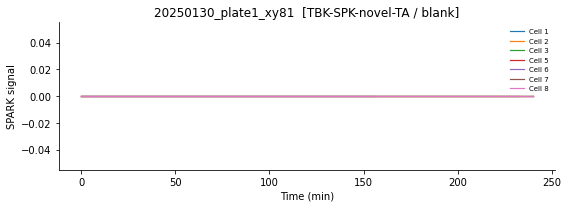

Saving run: 20250130_plate1_xy81
  spark_df: 393 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:22<00:00,  2.68it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (265.7 MB)
  done: 20250130_plate1_xy81

Processing: 20250130_plate1_xy85  [TBK-SPK-novel-TA / diABZI]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=87  max=3537  mean=138.5


CellSAM segmentation: 100%|████████████████████████████████████████| 61/61 [00:47<00:00,  1.28it/s]


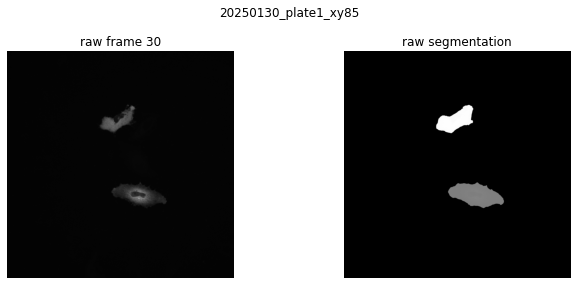

Post-processing masks: 100%|███████████████████████████████████████| 61/61 [00:05<00:00, 10.69it/s]


tracked_masks: (61, 1608, 1608)  cells=[1 2]


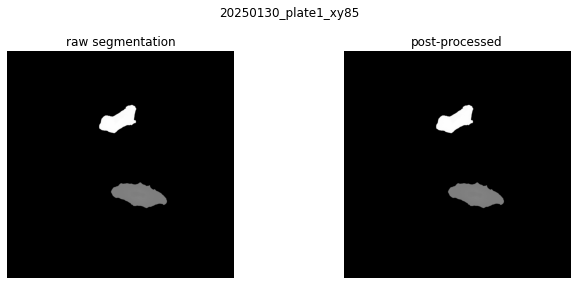

Quantifying SPARK signal: 100%|████████████████████████████████████| 61/61 [00:13<00:00,  4.63it/s]


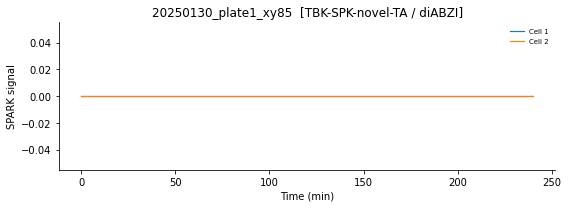

Saving run: 20250130_plate1_xy85
  spark_df: 122 rows × 14 cols
  tracked_masks: (61, 1608, 1608)


  Saving puncta coords: 100%|██████████████████████████████████████| 61/61 [00:13<00:00,  4.63it/s]



Done → ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5  (266.3 MB)
  done: 20250130_plate1_xy85

Processing: 20250130_plate1_xy89  [TBK-SPK-novel-TA / diABZI]

Selected: grayscale_direct  shape=(61, 1608, 1608)  min=86  max=1701  mean=129.1


CellSAM segmentation:   7%|██▋                                      | 4/61 [00:02<00:42,  1.34it/s]

In [ ]:
# ── main processing loop ─────────────────────────────────────────────────
import h5py

# skip runs already saved in the HDF5 to allow resuming
def already_processed(h5_path, key):
    if not os.path.exists(h5_path):
        return False
    with h5py.File(h5_path, 'r') as hf:
        return key in hf

for exp in EXPERIMENTS:
    try:
        path    = exp['path']
        if path == 'NOT FOUND':
            continue
        run_key = exp.get('run_key', os.path.splitext(os.path.basename(path))[0])
        sep     = '=' * 60
    
        # skip if already in HDF5
        if already_processed(OUTPUT_H5, run_key):
            print(f'Skipping {run_key} (already in HDF5)')
            continue
    
        print(f'\n{sep}')
        print(f'Processing: {run_key}  '
              f'[{exp["reporter"]} / {exp["condition"]}]')
        print(sep)
    
        # 1. load
        arr, meta = load_tiff_as_grayscale(path, channel=exp.get('channel'))
        read_frame_fn = make_read_frame(path, meta)
    
        # 2. segmentation
        masks_raw = run_cellsam_segmentation(model, arr, clip_max=SEG_PARAMS['clip_max'])
    
        # QC: mid-movie frame
        t_qc = arr.shape[0] // 2
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].imshow(arr[t_qc], cmap='gray'); axes[0].set_title(f'raw frame {t_qc}')
        axes[1].imshow(masks_raw[t_qc] * 2000 + arr[t_qc] * 0.1, cmap='gray')
        axes[1].set_title('raw segmentation')
        for ax in axes: ax.axis('off')
        plt.suptitle(run_key); plt.tight_layout(); plt.show()
    
        # 3. post-processing
        masks_clean, origin_frame = postprocess_masks(
            masks_raw,
            min_cell_size_px = SEG_PARAMS['min_cell_size_px'],
            iou_thresh       = SEG_PARAMS['iou_thresh'],
            ioq_thresh       = SEG_PARAMS['ioq_thresh'],
            dilation_px      = SEG_PARAMS['dilation_px'],
        )
        expected_ids = list(np.unique(origin_frame)[1:])
        masks_clean  = interpolate_missing_masks(
            masks_clean, expected_ids, max_gap=SEG_PARAMS['max_interp_gap'])
        tracked_masks = np.array(masks_clean)
        print(f'tracked_masks: {tracked_masks.shape}  '
              f'cells={np.unique(tracked_masks)[1:]}')
    
        # QC: post-processed
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].imshow(masks_raw[t_qc] * 2000 + arr[t_qc] * 0.1, cmap='gray')
        axes[0].set_title('raw segmentation')
        axes[1].imshow(tracked_masks[t_qc] * 2000 + arr[t_qc] * 0.1, cmap='gray')
        axes[1].set_title('post-processed')
        for ax in axes: ax.axis('off')
        plt.suptitle(run_key); plt.tight_layout(); plt.show()
    
        # 4. SPARK quantification
        # Use two-threshold method for dim IKK-SPK-novel TNFa/polyIC runs,
        # standard quantify_spark for everything else.
        use_dim = (exp['reporter'], exp['condition']) in DIM_REPORTER_CONDITIONS

        if not use_dim:
            df_spark = quantify_spark(
                path, tracked_masks, read_frame_fn,
                minutes_per_frame = exp['minutes_per_frame'],
                frame_offset_min  = exp['frame_offset_min'],
                **SPARK_PARAMS,
            )
        else:
            # ── two-threshold puncta detection for dim reporters ──────────────
            from skimage import measure
            from skimage.morphology import remove_small_objects
            from scipy.ndimage import label as scipy_label
            from tqdm import tqdm

            P          = SPARK_PARAMS_DIM
            n_frames   = arr.shape[0]
            records    = []
            mpf        = exp['minutes_per_frame']
            foff       = exp['frame_offset_min']

            for t in tqdm(range(n_frames), desc='Quantifying SPARK (dim)'):
                frame_img   = read_frame_fn(t)
                label_frame = tracked_masks[t]
                cell_ids    = np.unique(label_frame)
                cell_ids    = cell_ids[cell_ids != 0]

                for cid in cell_ids:
                    cell_mask  = (label_frame == cid)
                    cell_px    = frame_img[cell_mask]
                    cell_total = float(cell_px.sum())
                    cell_area  = int(cell_mask.sum())

                    # step 1: high-percentile seed
                    cell_thresh = np.percentile(cell_px, P['puncta_cell_percentile'])
                    seed_mask   = (frame_img >= cell_thresh) & cell_mask
                    seed_mask   = remove_small_objects(seed_mask,
                                                       min_size=P['min_puncta_size'])

                    if not seed_mask.any():
                        records.append({
                            'frame': t, 'time_min': foff + t * mpf,
                            'cell_id': int(cid), 'cell_area_px': cell_area,
                            'cell_total_int': cell_total,
                            'cell_thresh': float(cell_thresh),
                            'puncta_count': 0, 'puncta_area_px': 0,
                            'puncta_total_int': 0.0, 'spark_signal': 0.0,
                        })
                        continue

                    # step 2: expand seeds to low-floor boundary
                    low_mask    = (frame_img >= P['puncta_low_floor']) & cell_mask
                    seed_labels = measure.label(seed_mask)
                    expanded    = np.zeros_like(seed_mask, dtype=bool)
                    low_labeled, _ = scipy_label(low_mask)
                    for seed_lbl in range(1, seed_labels.max() + 1):
                        touching = np.unique(low_labeled[seed_labels == seed_lbl])
                        for lbl in touching[touching != 0]:
                            expanded |= (low_labeled == lbl)
                    expanded &= cell_mask

                    # step 3: filter by size and mean intensity
                    exp_labeled = measure.label(expanded)
                    final_mask  = np.zeros_like(expanded, dtype=bool)
                    for r in measure.regionprops(exp_labeled,
                                                  intensity_image=frame_img):
                        if (P['min_puncta_size'] <= r.area <= P['max_puncta_size']
                                and r.mean_intensity >= P['min_puncta_mean_int']):
                            final_mask[exp_labeled == r.label] = True

                    final_labeled = measure.label(final_mask)
                    puncta_total  = float(frame_img[final_mask].sum())
                    records.append({
                        'frame': t, 'time_min': foff + t * mpf,
                        'cell_id': int(cid), 'cell_area_px': cell_area,
                        'cell_total_int': cell_total,
                        'cell_thresh': float(cell_thresh),
                        'puncta_count': int(final_labeled.max()),
                        'puncta_area_px': int(final_mask.sum()),
                        'puncta_total_int': puncta_total,
                        'spark_signal': puncta_total / cell_total
                                        if cell_total > 0 else np.nan,
                    })

            df_spark = pd.DataFrame(records)
            # normalise to frame-0 (mirrors normalise_spark behaviour)
            f0_map = (df_spark[df_spark['frame'] == 0]
                      .set_index('cell_id')['spark_signal'].to_dict())
            df_spark['frame0_signal'] = df_spark['cell_id'].map(f0_map)
            df_spark['spark_norm_ctrl'] = df_spark['spark_signal']
            df_spark['reporter']  = exp['reporter']
            df_spark['condition'] = exp['condition']
            print(f'  dim quantification: {len(df_spark)} rows, '
                  f'{(df_spark.spark_signal > 0).sum()} non-zero')
    
        # 5. normalisation
        df_spark = normalise_spark(
            df_spark,
            norm_frame    = exp.get('norm_frame'),
            ctrl_cell_ids = exp.get('ctrl_cell_ids'),
        )
    
        # tag with reporter / condition for overlay notebook
        df_spark['reporter']  = exp['reporter']
        df_spark['condition'] = exp['condition']
    
        # quick trace preview
        fig, ax = plt.subplots(figsize=(8, 3))
        for cid, grp in df_spark.groupby('cell_id'):
            ax.plot(grp['time_min'], grp['spark_norm_ctrl'], lw=1.2, label=f'Cell {cid}')
        ax.set_xlabel('Time (min)'); ax.set_ylabel('SPARK signal')
        ax.legend(fontsize=7, frameon=False)
        ax.spines[['top','right']].set_visible(False)
        ax.set_title(f'{run_key}  [{exp["reporter"]} / {exp["condition"]}]')
        plt.tight_layout(); plt.show()
    
        # 6. save
        full_params = {
            **SPARK_PARAMS,
            'minutes_per_frame': exp['minutes_per_frame'],
            'frame_offset_min':  exp['frame_offset_min'],
            'norm_frame':        str(exp.get('norm_frame')),
            'ctrl_cell_ids':     str(exp.get('ctrl_cell_ids')),
            'reporter':          exp['reporter'],
            'condition':         exp['condition'],
        }
        save_to_hdf5(OUTPUT_H5, run_key, path, df_spark,
                     tracked_masks, read_frame_fn, full_params)
        print(f'  done: {run_key}')
    except:
        continue

print('\nAll experiments processed.')


In [23]:
path

'${SPARK_ACQUISITION_ROOT}/ExRai-imaging/20250130-plate1/20250130-plate1xy044c1.tif'

In [26]:
# ── verify all CSV entries are present in the HDF5 ───────────────────────────
import h5py, os, json
import pandas as pd

OUTPUT_H5 = '${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5'
CSV_V1    = './tif_file_mapping.csv'
CSV_V2    = './tif_file_mapping_v2.csv'
CSV_V3    = './tif_file_mapping_v3.csv'
CSV_V4    = './tif_file_mapping_v4.csv'

# rebuild combined run_key list (same logic as config cell)
df_v1 = pd.read_csv(CSV_V1).rename(columns={'matched_files': 'filepath'})
df_v1['run_key'] = df_v1['file_id']

def load_vn(csv_path):
    df = pd.read_csv(csv_path)
    df['run_key'] = (df['date'].astype(str) + '_' +
                     df['plate'].astype(str) + '_xy' +
                     df['xy'].astype(str).str.zfill(2))
    return df

df_v2 = load_vn(CSV_V2)
df_v3 = load_vn(CSV_V3)
df_v4 = load_vn(CSV_V4)

df_combined = pd.concat([
    df_v1[['run_key', 'reporter', 'condition', 'filepath']],
    df_v2[['run_key', 'reporter', 'condition', 'filepath']],
    df_v3[['run_key', 'reporter', 'condition', 'filepath']],
    df_v4[['run_key', 'reporter', 'condition', 'filepath']],
], ignore_index=True).drop_duplicates(subset='filepath')

# get HDF5 contents
if not os.path.exists(OUTPUT_H5):
    print(f'HDF5 not found: {OUTPUT_H5}')
else:
    with h5py.File(OUTPUT_H5, 'r') as hf:
        hdf5_keys = set(hf.keys())

        print(f'HDF5 path  : {OUTPUT_H5}')
        print(f'HDF5 size  : {os.path.getsize(OUTPUT_H5)/1e6:.1f} MB')
        print(f'HDF5 runs  : {len(hdf5_keys)}')
        print(f'CSV entries: {len(df_combined)} (after dedup)')

        # check presence
        df_combined['in_hdf5']     = df_combined['run_key'].isin(hdf5_keys)
        df_combined['file_exists'] = df_combined['filepath'].apply(os.path.exists)

        present = df_combined[df_combined['in_hdf5']]
        missing = df_combined[~df_combined['in_hdf5']]

        print(f'\n{"="*60}')
        print(f'Present in HDF5: {len(present)} / {len(df_combined)}')
        print(f'Missing from HDF5: {len(missing)}')

        if len(missing) > 0:
            print(f'\nMISSING RUNS:')
            for _, row in missing.iterrows():
                file_ok = 'file exists' if row['file_exists'] else 'FILE NOT FOUND'
                print(f'  {row["run_key"]:40s}  [{row["reporter"]} / {row["condition"]}]  {file_ok}')
        else:
            print('\nAll CSV entries are present in the HDF5.')

        # check for HDF5 keys not in any CSV (orphans)
        csv_keys = set(df_combined['run_key'])
        orphans  = hdf5_keys - csv_keys
        if orphans:
            print(f'\nHDF5 keys not in any CSV (orphans): {len(orphans)}')
            for k in sorted(orphans):
                print(f'  {k}')

        # per-run integrity check
        print(f'\n{"="*60}')
        print('Per-run integrity check:')
        issues = []
        for key in sorted(hdf5_keys):
            grp        = hf[key]
            has_df     = 'spark_df'      in grp
            has_masks  = 'tracked_masks' in grp
            has_puncta = 'puncta_coords' in grp
            has_meta   = 'metadata'      in grp.attrs
            n_rows     = len(grp['spark_df']['frame'][:]) if has_df else 0
            n_frames   = grp['tracked_masks'].shape[0]    if has_masks else 0
            ok = has_df and has_masks and has_puncta and has_meta and n_rows > 0
            status = 'OK' if ok else 'INCOMPLETE'
            if not ok:
                issues.append(key)
            print(f'  {status:12s}  {key:40s}  '
                  f'frames={n_frames}  spark_rows={n_rows}  '
                  f'df={has_df}  masks={has_masks}  '
                  f'puncta={has_puncta}  meta={has_meta}')

        print(f'\n{"="*60}')
        if issues:
            print(f'Incomplete runs ({len(issues)}) — re-run these:')
            for k in issues:
                print(f'  {k}')
            # optionally delete incomplete runs so they get reprocessed
            # with h5py.File(OUTPUT_H5, 'a') as hf_w:
            #     for k in issues:
            #         del hf_w[k]
            #         print(f'  deleted {k} from HDF5 for reprocessing')
        else:
            print('All runs passed integrity check.')

HDF5 path  : ${SPARK_ACQUISITION_ROOT}/spark_examples/spark_results.h5
HDF5 size  : 270.2 MB
HDF5 runs  : 188
CSV entries: 190 (after dedup)

Present in HDF5: 188 / 190
Missing from HDF5: 2

MISSING RUNS:
  20250126_plate1_xy62                      [TBK-SPK-novel-TA / diABZI]  FILE NOT FOUND
  20250130_plate1_xy44                      [TBK-SPK-1-TA / diABZI]  file exists

Per-run integrity check:
  OK            0725r1xy10                                frames=58  spark_rows=232  df=True  masks=True  puncta=True  meta=True
  OK            0725r1xy18                                frames=58  spark_rows=116  df=True  masks=True  puncta=True  meta=True
  OK            0731p2-46                                 frames=61  spark_rows=245  df=True  masks=True  puncta=True  meta=True
  OK            0731p2-57                                 frames=61  spark_rows=127  df=True  masks=True  puncta=True  meta=True
  OK            0731p2-62                                 frames=61  spark_rows=183 